In [6]:
import utils
import pandas as pd
import matplotlib.pyplot as plt
import importlib

In [33]:
importlib.reload(utils)

<module 'utils' from 'd:\\Universidad\\TPE - Ciencia de datos\\utils.py'>

In [20]:
data_path = 'results.csv'
df = pd.read_csv(data_path, low_memory=False)

meta_path = 'schema.csv'
metadatos = pd.read_csv(meta_path)

<h1 style="color: orange;">Analisis Exploratorio

<h3 style="color: violet;">Reduccion de variables a considerar durante el analisis de datos

In [10]:
clean_metadatos = metadatos

<h4><u>Variables de respuesta libre

Analizando el dataset de metadatos, vemos que son aquellas que tienen como tipo de respuesta admitida ('type'):
- TE (Text Entry)
- RO (Ranking Order) con ('sub') = TEXT

In [21]:
columns_save = [
    'WorkExp',
    'YearsCode',
    'ToolCountWork',
    'ToolCountPersonal',
    'CompTotal'
]
var_free = metadatos[(metadatos['type'] == 'TE') | (metadatos['sub'].str.contains('Text'))]
var_free = var_free[~var_free['qname'].isin(columns_save)] #salvamos aquellas que necesitamos
clean_metadatos.drop(var_free.index)
var_free[['qname', 'question', 'type', 'sub']].head(6)

,qname,question,type,sub
10,TechEndorse_13_TEXT,What attracts you to a technology or causes yo...,RO,Other (please specify): - Text
21,TechOppose_15_TEXT,What would turn you off or cause you to reject...,RO,Other (please specify): - Text
37,JobSatPoints_15_TEXT,Rank the following attributes of your current ...,RO,Other (please specify): - Text
48,SO_Actions_15_TEXT,"When visiting Stack Overflow, which following ...",RO,Other (write in): - Text
77,LanguagesHaveEntry,Was the programming language you use not liste...,TE,NaN
78,LanguagesWantEntry,Was the programming language you want to use n...,TE,NaN


Ademas, realizamos un promedio de porcentajes de valores nulos entre todas las columnas que descartamos y observamos que, en  promedio, el 84% de los valores de estas eran nulos. Observado tambien en el grafico de torta

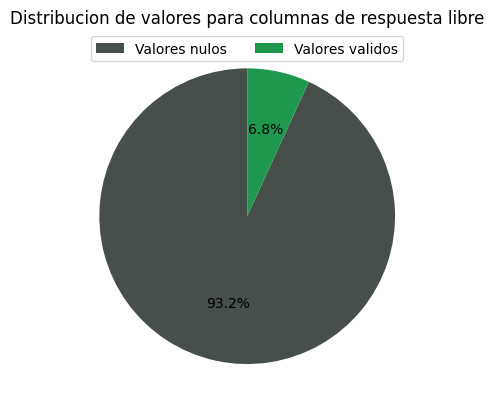

In [ ]:
utils.graficar_nulos(
    df,
    var_free['qname'].tolist(),
    labels=['Valores nulos', 'Valores validos'],
    title='Distribucion de valores para columnas de respuesta libre',
    colors=["#474f4a", '#1e984f']
)

In [25]:
j = percentage_null = 0
cant_null = cant_not_null = 0
for i in var_free['qname']:
    cant_null += df[i].isna().sum()
    cant_not_null += df[i].notna().sum()
    percentage_null += df[i].isna().mean()
    j += 1

percentage_null /= j
print(f"Promedio: {percentage_null} - Cantidad nulos: {cant_null} - Cantidad no nulos: {cant_not_null} - Total: {cant_null + cant_not_null}")

Promedio: 0.93152710861743 - Cantidad nulos: 1283037 - Cantidad no nulos: 94311 - Total: 1377348


In [26]:
df = df.drop(columns=var_free['qname'].to_list(), errors="ignore")

<h4><u>Variables asociadas al uso de StackOverflow

Analizando el dataset de metadatos, vemos que son aquellas que comienzan con 'SO' en el nombre de variable

In [27]:
var_SO = metadatos[metadatos['qname'].str.startswith('SO')]
clean_metadatos.drop(var_SO.index)
df = df.drop(columns=var_SO['qname'].to_list(), errors="ignore")
var_SO[['qname', 'question']].head(3)

,qname,question
38,SO_Actions_1,"When visiting Stack Overflow, which following ..."
39,SO_Actions_16,"When visiting Stack Overflow, which following ..."
40,SO_Actions_3,"When visiting Stack Overflow, which following ..."


<h3 style="color: violet;">Distribucion de variables

In [41]:
def barras(col, umbral=500, map=None, cut=0, ax=None):
    if ax is None:
        _, ax = plt.subplots()

    if cut:
        frecuencias = df[col].str[:cut].value_counts()
    else:
        frecuencias = df[col].value_counts()

    frecuencias_agrupadas = frecuencias[frecuencias >= umbral].copy()
    otros = frecuencias[frecuencias < umbral].sum()

    if otros > 0:
        frecuencias_agrupadas['Otros'] = otros

    frecuencias_agrupadas.plot(
        kind='bar',
        edgecolor='black',
        ax=ax
    )

    ax.set_title(col)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)

    return ax

In [54]:
def histEs(ax=None):
    if ax is None:
        _, ax = plt.subplots()


    comp = df['CompTotal'].dropna()
    limite = comp.quantile(0.85)
    comp[comp <= limite].hist(
        figsize=(10, 5),
        bins=5,
        edgecolor='black',
        ax=ax
    )
    ax.set_title('CompTotal:85%')
    ax.set_xlabel('')
    ax.grid(False)
    return ax

<h4><u>Demografía y Perfil Laboral

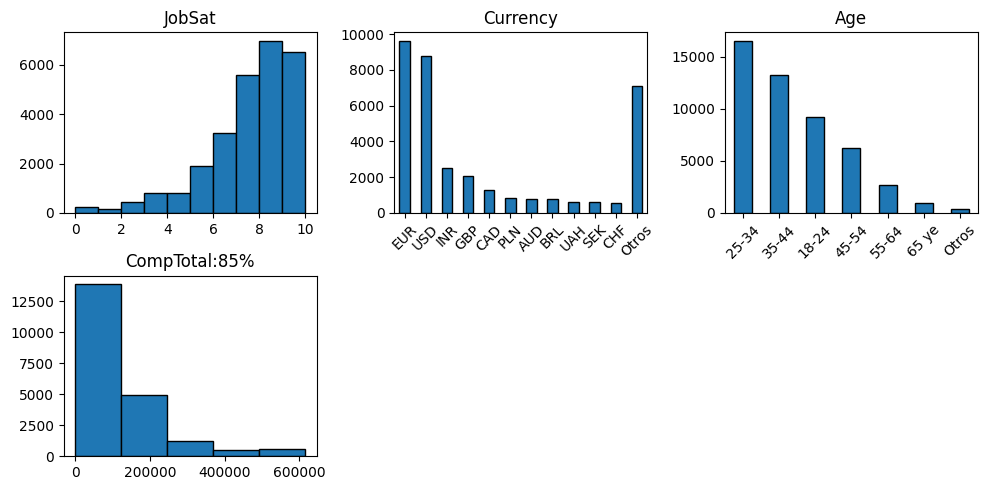

In [56]:
columnas = [
    'MainBranch',
    'Age',
    'Country',
    'Currency',
    'EdLevel',
    'Employment',
    'EmploymentAddl',
    'Industry',
    'OrgSize',
    'DevType',
    'ICorPM',
    'RemoteWork',
    'JobSat',
    'NewRole'
]
resultado = utils.graficar_histogramas(
    df,
    columnas,
    bins=10,
    figsize_por_grafico=(15, 15),
    n_extras=3
)

if resultado is not None:
    fig, axes = resultado
    inicio = len(df[columnas].select_dtypes(include='number').columns)
    barras('Currency', cut=3, ax=axes.flat[inicio])
    barras('Age', cut=5, ax=axes.flat[inicio+1])
    histEs(ax=axes.flat[inicio+2])

    fig.tight_layout()
    plt.show()